# CSE475 — Task 2: Proposed Model (Host-Graph GNN)
## TON_IoT (network) · Track 1: Graph Neural Network · Group 07, Section 01

**File:** `code/task2/Group07_TONIoT_task2_proposed_model.ipynb`

We turn the traffic into a graph — **hosts are nodes, flows are edges** — and train a graph
neural network that classifies each edge (each flow). It uses the same data, duplicate
removal, splits and preprocessing as the baselines notebook (the split fingerprint printed
below must match), so results are directly comparable.

Runs on **CPU** in a few minutes; no GPU needed.

## 0 · Setup and data

In [1]:
import os, json, time, pickle, warnings, random, ipaddress, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "figure.autolayout": True,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.grid": True,
                     "grid.alpha": .25, "legend.frameon": False})
sns.set_palette("colorblind")
OUT = Path("figures"); OUT.mkdir(exist_ok=True)
def save(fig, name): fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
def reading(t): print("\nReading: " + t)

import torch, torch.nn as nn, torch.nn.functional as F
torch.manual_seed(SEED); torch.set_num_threads(max(1, os.cpu_count() or 1))
print("torch", torch.__version__)

torch 2.11.0+cu130


In [2]:
# ---- locate and load (same logic as Task 1) ----
def clean_cols(cols):
    return [str(c).replace("\ufeff", "").replace("ï»¿", "").strip().lower() for c in cols]

DATA_PATH = "/kaggle/input/datasets/j21saksham/ton-iot-network-intrusion-detection/train_test_network.csv"
print("Using:", DATA_PATH)

raw = pd.read_csv(DATA_PATH, encoding="latin-1", low_memory=False)
raw.columns = clean_cols(raw.columns)
df = raw.replace({"-": np.nan, "": np.nan})
df["type"] = df["type"].astype(str).str.strip().str.lower()
df["label"] = (df["type"] != "normal").astype(int)
for c in df.columns:
    if c in ("type", "src_ip", "dst_ip") or pd.api.types.is_numeric_dtype(df[c]):
        continue
    conv = pd.to_numeric(df[c], errors="coerce")
    if df[c].notna().any() and conv.notna().sum() >= 0.95 * df[c].notna().sum():
        df[c] = conv

n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)          # Task 1 §C: remove exact duplicates first
print(f"rows: {n0:,} -> {len(df):,} after removing {n0 - len(df):,} exact duplicates")

ID_COLS = [c for c in ["ts", "src_ip", "src_port", "dst_ip", "dst_port"] if c in df.columns]
TARGETS = ["label", "type"]
cand = [c for c in df.columns if c not in ID_COLS + TARGETS]
NUM = [c for c in cand if pd.api.types.is_numeric_dtype(df[c])]
OBJ = [c for c in cand if c not in NUM]
TEXT = [c for c in OBJ if df[c].nunique() > 100]           # free text, e.g. dns_query: not used
CAT = [c for c in OBJ if c not in TEXT]
CLASSES = sorted(df["type"].unique())
print(f"numeric {len(NUM)}, categorical {len(CAT)}, dropped free-text {TEXT}, identifiers {ID_COLS}")
print("classes:", CLASSES)

Using: /kaggle/input/datasets/j21saksham/ton-iot-network-intrusion-detection/train_test_network.csv
rows: 211,043 -> 190,474 after removing 20,569 exact duplicates
numeric 17, categorical 20, dropped free-text ['dns_query'], identifiers ['src_ip', 'src_port', 'dst_ip', 'dst_port']
classes: ['backdoor', 'ddos', 'dos', 'injection', 'mitm', 'normal', 'password', 'ransomware', 'scanning', 'xss']


In [3]:
# ---- two evaluation protocols ---------------------------------------------
from sklearn.model_selection import train_test_split, StratifiedGroupKFold

# Protocol M (multiclass): stratified flow-level 70 / 15 / 15.
idx = np.arange(len(df))
m_tr, m_tmp = train_test_split(idx, test_size=0.30, stratify=df["type"], random_state=SEED)
m_va, m_te = train_test_split(m_tmp, test_size=0.50, stratify=df["type"].iloc[m_tmp], random_state=SEED)

# Protocol B (binary): no source host shared between train, validation and test.
groups = df["src_ip"].astype(str).values
yb = df["label"].values
def host_split(seed):
    folds = [te for _, te in StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=seed).split(idx, yb, groups)]
    te, va = folds[0], folds[1]
    return np.setdiff1d(idx, np.concatenate([te, va])), va, te
for s in range(50):
    b_tr, b_va, b_te = host_split(s)
    if all(len(np.unique(yb[p])) == 2 for p in (b_tr, b_va, b_te)):
        B_SEED = s; break
assert not (set(groups[b_tr]) & set(groups[b_te])) and not (set(groups[b_tr]) & set(groups[b_va]))

SPLIT = {"M": (m_tr, m_va, m_te), "B": (b_tr, b_va, b_te)}
for k, (a, b, c) in SPLIT.items():
    tgt = df["type"] if k == "M" else df["label"]
    print(f"Protocol {k}: train {len(a):,} | val {len(b):,} | test {len(c):,}"
          + (f" | source hosts {len(set(groups[a]))}/{len(set(groups[b]))}/{len(set(groups[c]))}" if k == "B" else ""))
    print("   test class counts:", tgt.iloc[c].value_counts().to_dict())
SPLIT_HASH = hashlib.md5(np.concatenate([m_te, b_te]).tobytes()).hexdigest()[:10]
print("split fingerprint (must match in both Task 2 notebooks):", SPLIT_HASH)

Protocol M: train 133,331 | val 28,571 | test 28,572
   test class counts: {'normal': 6306, 'scanning': 3000, 'ddos': 2999, 'injection': 2995, 'password': 2980, 'dos': 2849, 'backdoor': 2807, 'xss': 2270, 'ransomware': 2210, 'mitm': 156}
Protocol B: train 122,776 | val 41,432 | test 26,266 | source hosts 37/7/7
   test class counts: {0: 19883, 1: 6383}
split fingerprint (must match in both Task 2 notebooks): 70dd7b8009


In [4]:
# ---- preprocessing: fitted on the training split only ---------------------
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

def log1p_clip(X):
    return np.log1p(np.clip(X, 0, None))

def make_prep():
    num = Pipeline([("log", FunctionTransformer(log1p_clip)),
                    ("imp", SimpleImputer(strategy="median", add_indicator=True)),   # flags 'field not applicable'
                    ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="none")),
                    ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                                         sparse_output=False))])
    return ColumnTransformer([("num", num, NUM), ("cat", cat, CAT)])

def prepare(protocol):
    tr, va, te = SPLIT[protocol]
    prep = make_prep().fit(df.iloc[tr][NUM + CAT].astype({c: str for c in CAT}))
    X = lambda ix: prep.transform(df.iloc[ix][NUM + CAT].astype({c: str for c in CAT})).astype(np.float32)
    return prep, X(tr), X(va), X(te)

In [5]:
# ---- metrics (course brief §6.1) ------------------------------------------
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve)
from sklearn.preprocessing import label_binarize

def evaluate(y_true, y_pred, scores, labels):
    """scores: (n, n_classes) probabilities or decision values, columns ordered as `labels`."""
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    out = {"accuracy": accuracy_score(y_true, y_pred), "macro_precision": p, "macro_recall": r,
           "macro_f1": f, "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0)}
    if len(labels) == 2:
        s = scores[:, 1] if scores.ndim == 2 else scores
        out["roc_auc"] = roc_auc_score(y_true, s); out["pr_auc"] = average_precision_score(y_true, s)
    else:
        Y = label_binarize(y_true, classes=labels)
        keep = Y.sum(0) > 0
        out["roc_auc"] = roc_auc_score(Y[:, keep], scores[:, keep], average="macro")      # one-vs-rest
        out["pr_auc"] = average_precision_score(Y[:, keep], scores[:, keep], average="macro")
    return out

def plot_curves(y_true, scores, labels, title, name):
    """One-vs-rest ROC and precision-recall curves."""
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    if len(labels) == 2:
        s = scores[:, 1] if scores.ndim == 2 else scores
        fpr, tpr, _ = roc_curve(y_true, s); pr, rc, _ = precision_recall_curve(y_true, s)
        ax[0].plot(fpr, tpr, label=f"AUC {roc_auc_score(y_true, s):.3f}")
        ax[1].plot(rc, pr, label=f"AP {average_precision_score(y_true, s):.3f}")
    else:
        Y = label_binarize(y_true, classes=list(range(len(labels))))   # y_true is integer-coded
        for i, c in enumerate(labels):
            if Y[:, i].sum() == 0: continue
            fpr, tpr, _ = roc_curve(Y[:, i], scores[:, i]); pr, rc, _ = precision_recall_curve(Y[:, i], scores[:, i])
            ax[0].plot(fpr, tpr, lw=1.2, label=f"{c} ({roc_auc_score(Y[:, i], scores[:, i]):.3f})")
            ax[1].plot(rc, pr, lw=1.2, label=f"{c} ({average_precision_score(Y[:, i], scores[:, i]):.3f})")
    ax[0].plot([0, 1], [0, 1], "k--", lw=.8)
    ax[0].set(title="ROC (one-vs-rest)", xlabel="False positive rate", ylabel="True positive rate")
    ax[1].set(title="Precision-recall (one-vs-rest)", xlabel="Recall", ylabel="Precision")
    for a in ax: a.legend(fontsize=7)
    fig.suptitle(title, fontweight="bold"); save(fig, name); plt.show()

def plot_cm(y_true, y_pred, labels, title, name, ax=None):
    cm = confusion_matrix(y_true, y_pred, labels=labels, normalize="true")
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(7.5, 6))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=labels, yticklabels=labels,
                ax=ax, cbar=False, annot_kws={"size": 7}, vmin=0, vmax=1)
    ax.set(title=title, xlabel="Predicted", ylabel="True")
    if own: save(fig, name); plt.show()

## 1 · Graph construction

| Graph part | In our data | Why |
|---|---|---|
| **Node** | one host (IP address) | the real machines on the network |
| **Node features** | none — every node starts from the same learned vector | a host is described only by its traffic, so the model cannot memorise an address |
| **Edge** | one flow, directed source → destination | a flow *is* a relationship between two hosts |
| **Edge features** | the flow's preprocessed features (bytes, packets, duration, protocol, …) | what each flow measured |
| **Prediction** | a class for every edge | we label flows, not machines (edge classification) |

We use the IP alone, not IP + port: source ports change on every connection, so IP:port
nodes would almost never repeat and the graph would have no neighbourhoods.

**No leakage through the graph.** The model is trained on a graph made only of training flows.
To score validation or test flows, those flows are added as new edges *without labels*: the
model sees their features, never their answers. Identifiers are never features — the IP only
decides which flows meet at the same node.

In [6]:
hosts = pd.Index(pd.unique(pd.concat([df["src_ip"], df["dst_ip"]]).astype(str)))
SRC = torch.tensor(hosts.get_indexer(df["src_ip"].astype(str)), dtype=torch.long)
DST = torch.tensor(hosts.get_indexer(df["dst_ip"].astype(str)), dtype=torch.long)
N_NODES = len(hosts)
print(f"nodes (hosts): {N_NODES:,} | edges (flows): {len(df):,}")
for k, (a, b, c) in SPLIT.items():
    print(f"Protocol {k}: training graph {len(a):,} edges over {len(np.unique(np.r_[SRC[a], DST[a]])):,} hosts")

nodes (hosts): 776 | edges (flows): 190,474
Protocol M: training graph 133,331 edges over 703 hosts
Protocol B: training graph 122,776 edges over 689 hosts


## 2 · The model

Each layer updates every host from the flows touching it, then a classifier reads the flow:

1. **Message.** For every flow *u → v*, combine the sending host's current vector with the
   flow's features: *m = ReLU(W · [h_u ‖ x_uv])*. Separate weights for incoming and outgoing
   flows keep direction (being scanned is not the same as scanning).
2. **Aggregate.** Each host averages the messages from all its flows. Averaging works for
   hosts with 3 flows or 30,000, and does not depend on order.
3. **Update.** *h_v ← LayerNorm(ReLU(W_self · h_v + aggregate))*. Two layers, so a host's vector
   reflects its neighbours' neighbours.
4. **Classify the flow.** Concatenate *[h_source ‖ h_destination ‖ x_flow]* and pass it through
   a small MLP. The flow's own features go straight to the classifier, so the graph adds host
   context on top of what a flat model sees.

This follows E-GraphSAGE (Lo et al., 2022) — edge features in message passing, edge
classification — with two changes: direction-aware messages, and the flow's own features in
the classifier.

**Control model.** The same network with **zero** message-passing layers sees only the flow
features — an MLP with the same head. If the GNN beats it, the gain comes from the graph.

In [7]:
class EdgeSAGELayer(nn.Module):
    """One round of message passing that uses edge (flow) features."""
    def __init__(self, d_node, d_edge, d_out, dropout):
        super().__init__()
        self.msg_in = nn.Linear(d_node + d_edge, d_out)    # message to the destination
        self.msg_out = nn.Linear(d_node + d_edge, d_out)   # message to the source
        self.self_lin = nn.Linear(d_node, d_out)
        self.norm = nn.LayerNorm(d_out); self.drop = nn.Dropout(dropout)

    def forward(self, h, e_in, e_out):
        """e_in / e_out: (src, dst, features) of the flows each host aggregates as receiver / sender.
        In training these are a random sample of each host's flows; in evaluation, all of them."""
        n = h.size(0)
        (s1, d1, x1), (s2, d2, x2) = e_in, e_out
        m_in = F.relu(self.msg_in(torch.cat([h[s1], x1], 1)))      # sender's state + flow -> receiver
        m_out = F.relu(self.msg_out(torch.cat([h[d2], x2], 1)))    # receiver's state + flow -> sender
        agg = torch.zeros(n, m_in.size(1)).index_add_(0, d1, m_in).index_add_(0, s2, m_out)
        deg = (torch.bincount(d1, minlength=n) + torch.bincount(s2, minlength=n)).clamp(min=1)
        return self.drop(self.norm(F.relu(self.self_lin(h) + agg / deg.unsqueeze(1))))

class HostGraphGNN(nn.Module):
    def __init__(self, d_edge, n_classes, hidden=64, n_layers=2, dropout=0.2):
        super().__init__()
        self.h0 = nn.Parameter(torch.ones(1, hidden))          # same start vector for every host
        self.layers = nn.ModuleList([EdgeSAGELayer(hidden, d_edge, hidden, dropout) for _ in range(n_layers)])
        self.head = nn.Sequential(nn.Linear(2 * hidden + d_edge, hidden), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(hidden, n_classes))

    def embed(self, n_nodes, e_in, e_out):
        h = self.h0.expand(n_nodes, -1)
        for layer in self.layers:
            h = layer(h, e_in, e_out)
        return h

    def classify(self, h, src, dst, xe):
        return self.head(torch.cat([h[src], h[dst], xe], 1))

print(HostGraphGNN(d_edge=40, n_classes=10))

HostGraphGNN(
  (layers): ModuleList(
    (0-1): 2 x EdgeSAGELayer(
      (msg_in): Linear(in_features=104, out_features=64, bias=True)
      (msg_out): Linear(in_features=104, out_features=64, bias=True)
      (self_lin): Linear(in_features=64, out_features=64, bias=True)
      (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (drop): Dropout(p=0.2, inplace=False)
    )
  )
  (head): Sequential(
    (0): Linear(in_features=168, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)


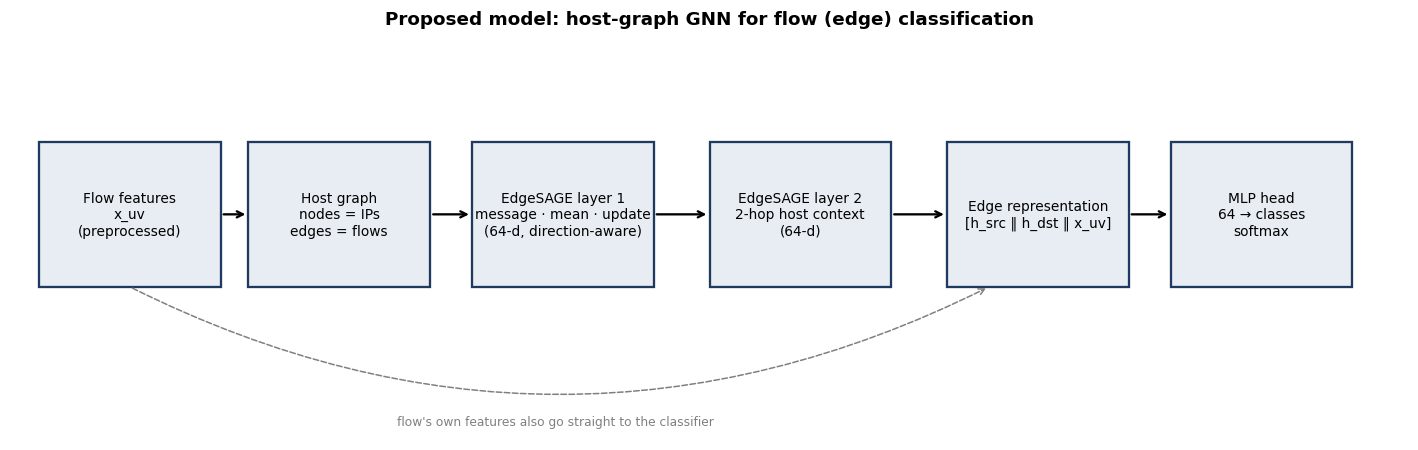

In [8]:
# Architecture diagram (matches the code above)
fig, ax = plt.subplots(figsize=(13, 4.2)); ax.axis("off")
boxes = [(0.02, "Flow features\nx_uv\n(preprocessed)"), (0.17, "Host graph\nnodes = IPs\nedges = flows"),
         (0.33, "EdgeSAGE layer 1\nmessage · mean · update\n(64-d, direction-aware)"),
         (0.50, "EdgeSAGE layer 2\n2-hop host context\n(64-d)"),
         (0.67, "Edge representation\n[h_src ‖ h_dst ‖ x_uv]"),
         (0.83, "MLP head\n64 → classes\nsoftmax")]
for x, t in boxes:
    ax.add_patch(plt.Rectangle((x, .3), .13, .4, fc="#E8EDF3", ec="#1F3A5F", lw=1.5))
    ax.text(x + .065, .5, t, ha="center", va="center", fontsize=9)
for (x, _), (x2, _) in zip(boxes, boxes[1:]):
    ax.annotate("", xy=(x2, .5), xytext=(x + .13, .5), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.annotate("", xy=(.70, .3), xytext=(.085, .3), arrowprops=dict(arrowstyle="->", lw=1, ls="--",
            connectionstyle="arc3,rad=.25", color="grey"))
ax.set_ylim(-.12, 1); ax.text(.39, -.08, "flow's own features also go straight to the classifier", ha="center", fontsize=8, color="grey")
ax.set_title("Proposed model: host-graph GNN for flow (edge) classification", fontweight="bold")
save(fig, "gnn_architecture"); plt.show()

## 3 · Training procedure

| Setting | Value | Why |
|---|---|---|
| Hidden size | 64 | small graph (hundreds of hosts) — larger adds little |
| Layers | 2 | host + neighbours' neighbours |
| Dropout | 0.2 | regularisation |
| Neighbour sampling | up to 32 flows per host per direction, re-drawn every step | GraphSAGE-style: many cheap updates, and hub hosts with thousands of flows cannot dominate |
| Mini-batch | 2,048 target flows per step | about 65 weight updates per epoch |
| Optimiser | Adam, lr 0.002 (halved when validation stalls), weight decay 1e-5 | standard |
| Loss | cross-entropy with balanced class weights | MITM is 48× rarer than Normal |
| Epochs | up to 40, early stopping (patience 6) | |
| Model selection | best **validation** macro-F1 | test set untouched until the end |

At evaluation time every host aggregates **all** of its flows (no sampling), so predictions
are deterministic.

In [9]:
def to_t(a): return torch.tensor(np.asarray(a))

class Neighbourhoods:
    """Per-host lists of incident flows, for fast GraphSAGE-style neighbour sampling."""
    def __init__(self, edge_ids):
        self.e = torch.as_tensor(edge_ids)
        self.s, self.d = SRC[self.e], DST[self.e]
    def sample(self, k, gen):
        out = []
        for key in (self.d, self.s):                  # receiver side, then sender side
            r = torch.rand(len(key), generator=gen)
            order = torch.argsort(key.double() * 2 + r.double())          # group by host, random within host
            g = key[order]
            first = torch.searchsorted(g, g, right=False)
            keep = order[(torch.arange(len(g)) - first) < k]               # at most k flows per host
            out.append(self.e[keep])
        return out
    def full(self):
        return [self.e, self.e]

def train_gnn(protocol, labels, ycol, n_layers=2, hidden=64, k=32, batch=2048, epochs=40,
              patience=6, lr=2e-3, tag=""):
    torch.manual_seed(SEED); gen = torch.Generator().manual_seed(SEED)
    tr, va, te = SPLIT[protocol]
    prep, Xtr, Xva, Xte = prepare(protocol)
    X = torch.zeros(len(df), Xtr.shape[1])
    X[tr], X[va], X[te] = to_t(Xtr), to_t(Xva), to_t(Xte)
    enc = {c: i for i, c in enumerate(labels)}
    Y = torch.tensor(df[ycol].map(enc).values, dtype=torch.long)
    E = lambda ids: (SRC[ids], DST[ids], X[ids])

    nb_tr = Neighbourhoods(tr)                              # training graph: training flows only
    full_va = [E(torch.as_tensor(np.concatenate([tr, va])))] * 2   # + validation flows, no labels
    full_te = [E(torch.as_tensor(np.concatenate([tr, te])))] * 2   # + test flows, no labels

    model = HostGraphGNN(X.shape[1], len(labels), hidden, n_layers)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    w = torch.tensor(len(tr) / (len(labels) * np.bincount(Y[tr].numpy(), minlength=len(labels)).clip(1)),
                     dtype=torch.float32)
    tr_t, va_t, te_t = (torch.as_tensor(a) for a in (tr, va, te))

    def predict(full, ids):
        model.eval()
        with torch.no_grad():
            h = model.embed(N_NODES, *full)
            return model.classify(h, SRC[ids], DST[ids], X[ids])

    best, best_state, wait, hist = -1, None, 0, []
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); perm = tr_t[torch.randperm(len(tr_t), generator=gen)]; losses = []
        for b0 in range(0, len(perm), batch):
            tgt = perm[b0:b0 + batch]
            e_in, e_out = nb_tr.sample(k, gen)
            h = model.embed(N_NODES, E(e_in), E(e_out))
            loss = F.cross_entropy(model.classify(h, SRC[tgt], DST[tgt], X[tgt]), Y[tgt], weight=w)
            opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
        f = f1_score(Y[va].numpy(), predict(full_va, va_t).argmax(1).numpy(), average="macro")
        sched.step(f); hist.append((ep, float(np.mean(losses)), f))
        if f > best: best, best_state, wait = f, {kk: v.clone() for kk, v in model.state_dict().items()}, 0
        else: wait += 1
        if wait >= patience: break
    train_s = time.time() - t0
    model.load_state_dict(best_state)

    t0 = time.time(); logits = predict(full_te, te_t); infer = time.time() - t0
    prob = logits.softmax(1).numpy(); pred = prob.argmax(1); yte = Y[te].numpy()
    r = evaluate(yte, pred, prob, list(range(len(labels))))
    r.update(val_macro_f1=best, train_s=train_s, epochs=len(hist), infer_ms_per_1k=infer / len(te) * 1e6,
             params=sum(p.numel() for p in model.parameters()))
    print(f"[{protocol}{tag}] layers={n_layers}: {len(hist)} epochs, val macro-F1 {best:.4f}, "
          f"test macro-F1 {r['macro_f1']:.4f}, {train_s:.1f}s, {r['params']:,} parameters")
    return model, r, hist, (yte, pred, prob), prep

## 4 · Protocol M — 10-class, flow-level split

In [10]:
gnn_M, r_gnn_M, hist_M, out_M, prep_M = train_gnn("M", CLASSES, "type", n_layers=2)
ctl_M, r_ctl_M, _, out_ctl_M, _ = train_gnn("M", CLASSES, "type", n_layers=0, tag=" control")

[M] layers=2: 13 epochs, val macro-F1 0.6220, test macro-F1 0.6262, 61.2s, 65,866 parameters
[M control] layers=0: 40 epochs, val macro-F1 0.8827, test macro-F1 0.8841, 119.8s, 15,306 parameters


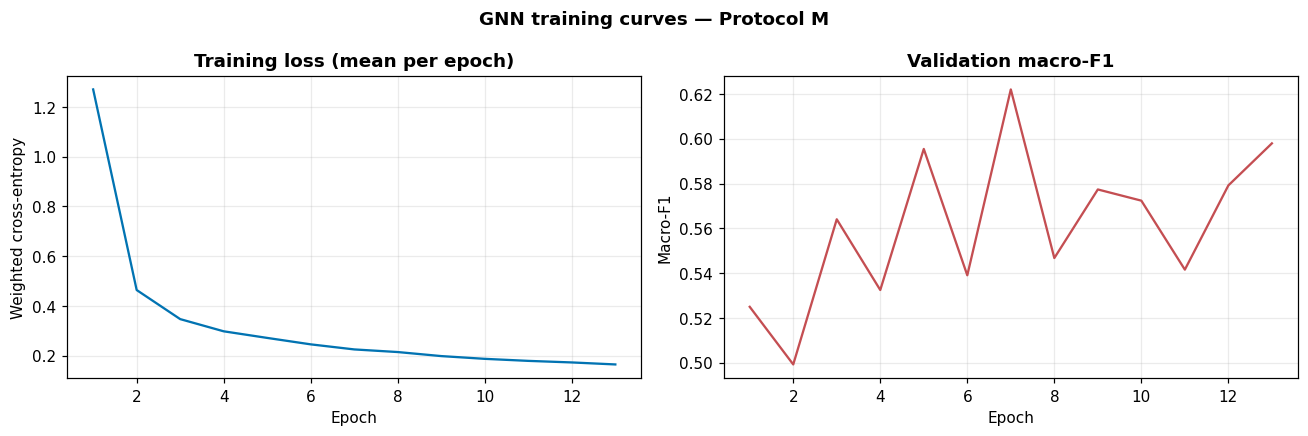

              precision    recall  f1-score   support

    backdoor     0.9979    0.9993    0.9986      2807
        ddos     0.9592    0.0313    0.0607      2999
         dos     0.8571    0.5093    0.6389      2849
   injection     0.5936    0.5843    0.5889      2995
        mitm     0.3615    0.9872    0.5292       156
      normal     1.0000    0.9989    0.9994      6306
    password     0.9793    0.1111    0.1995      2980
  ransomware     0.9991    0.9973    0.9982      2210
    scanning     0.6825    0.9380    0.7901      3000
         xss     0.2975    1.0000    0.4586      2270

    accuracy                         0.7060     28572
   macro avg     0.7728    0.7157    0.6262     28572
weighted avg     0.8438    0.7060    0.6708     28572



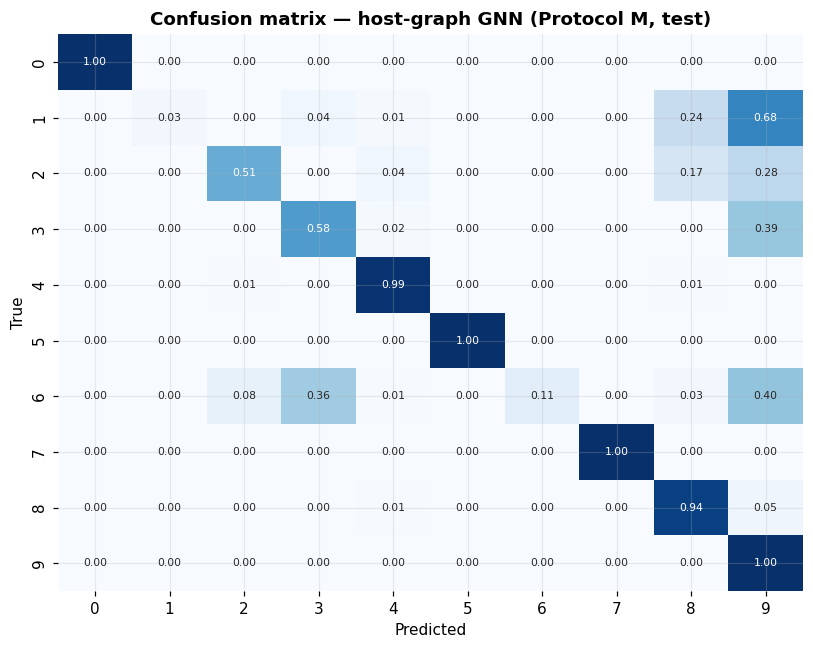

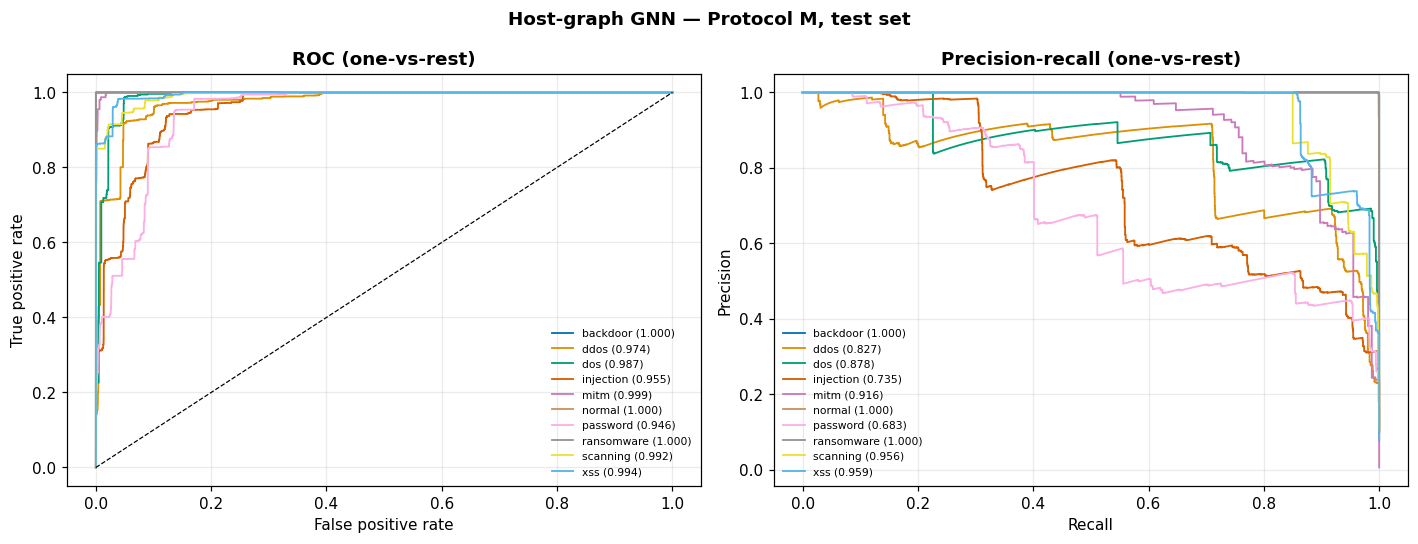

In [11]:
h = np.array(hist_M)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h[:, 0], h[:, 1]); ax[0].set(title="Training loss (mean per epoch)", xlabel="Epoch", ylabel="Weighted cross-entropy")
ax[1].plot(h[:, 0], h[:, 2], color="#C44E52"); ax[1].set(title="Validation macro-F1", xlabel="Epoch", ylabel="Macro-F1")
fig.suptitle("GNN training curves — Protocol M", fontweight="bold"); save(fig, "gnn_M_training"); plt.show()
yte, pred, prob = out_M
print(classification_report(yte, pred, target_names=CLASSES, digits=4, zero_division=0))
plot_cm(yte, pred, list(range(len(CLASSES))), "Confusion matrix — host-graph GNN (Protocol M, test)", "gnn_M_cm")
plot_curves(yte, prob, CLASSES, "Host-graph GNN — Protocol M, test set", "gnn_M_curves")

### Reference baseline on the identical split

XGBoost is retrained here on exactly the same split and features so the comparison is
like-for-like. (The full baseline study is in the baselines notebook.)

In [12]:
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight
def xgb_ref(protocol, labels, ycol):
    tr, va, te = SPLIT[protocol]; _, Xtr, Xva, Xte = prepare(protocol)
    enc = {c: i for i, c in enumerate(labels)}; y = df[ycol].map(enc).values
    m = XGBClassifier(n_estimators=400, max_depth=8, learning_rate=0.1, tree_method="hist", subsample=0.9,
                      colsample_bytree=0.8, n_jobs=-1, random_state=SEED, early_stopping_rounds=30,
                      eval_metric="mlogloss" if len(labels) > 2 else "logloss")
    t0 = time.time()
    m.fit(Xtr, y[tr], sample_weight=compute_sample_weight("balanced", y[tr]), eval_set=[(Xva, y[va])], verbose=False)
    ts = time.time() - t0
    prob = m.predict_proba(Xte); pred = prob.argmax(1)
    r = evaluate(y[te], pred, prob, list(range(len(labels))))
    r.update(val_macro_f1=f1_score(y[va], m.predict(Xva), average="macro"), train_s=ts)
    return r, (y[te], pred, prob)
r_xgb_M, out_xgb_M = xgb_ref("M", CLASSES, "type")

cols = ["val_macro_f1", "accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1", "roc_auc", "pr_auc", "train_s"]
cmpM = pd.DataFrame({"XGBoost (best baseline)": r_xgb_M, "MLP control (no graph)": r_ctl_M,
                     "Host-graph GNN (ours)": r_gnn_M}).T[cols].astype(float)
cmpM.round(4).to_csv("comparison_M.csv"); cmpM.round(4)

,val_macro_f1,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc,pr_auc,train_s
XGBoost (best baseline),0.9553,0.9790,0.9404,0.9665,0.9509,0.9794,0.9994,0.9785,40.4830
MLP control (no graph),0.8827,0.9393,0.8788,0.9337,0.8841,0.9442,0.9952,0.9269,119.8358
Host-graph GNN (ours),0.6220,0.7060,0.7728,0.7157,0.6262,0.6708,0.9848,0.8954,61.2407


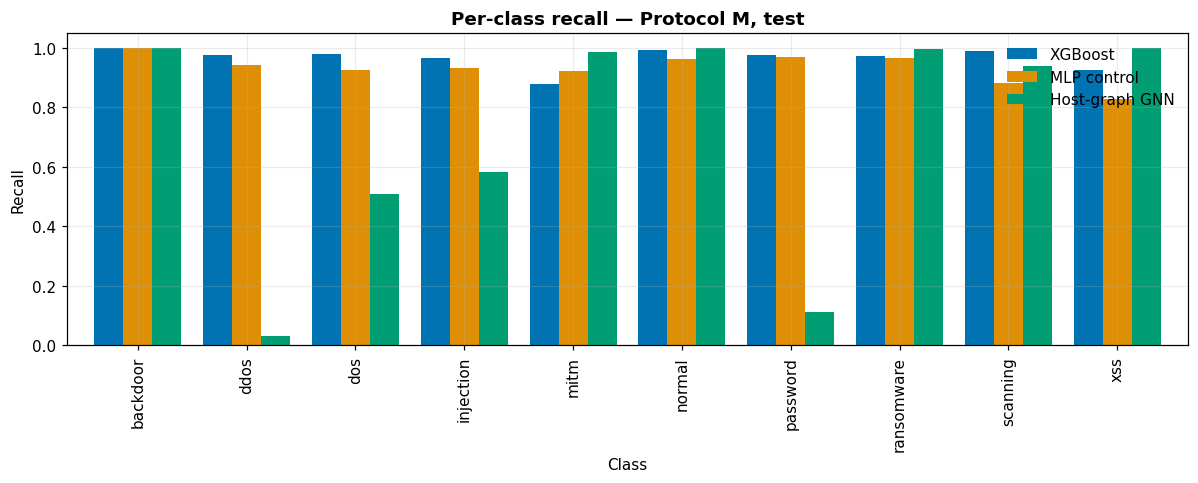


Reading: Graph vs no-graph control: -0.2579 macro-F1. GNN vs XGBoost: -0.3247. The first number isolates what host structure adds; the second is the bar from the brief.


,XGBoost,MLP control,Host-graph GNN
backdoor,1.000,0.999,0.999
ddos,0.978,0.944,0.031
dos,0.981,0.927,0.509
injection,0.966,0.931,0.584
mitm,0.878,0.923,0.987
normal,0.994,0.962,0.999
password,0.978,0.971,0.111
ransomware,0.973,0.966,0.997
scanning,0.992,0.883,0.938
xss,0.925,0.830,1.000


In [13]:
rec = pd.DataFrame({n: precision_recall_fscore_support(o[0], o[1], labels=range(len(CLASSES)), zero_division=0)[1]
                    for n, o in [("XGBoost", out_xgb_M), ("MLP control", out_ctl_M), ("Host-graph GNN", out_M)]},
                   index=CLASSES)
fig, ax = plt.subplots(figsize=(11, 4.5)); rec.plot(kind="bar", ax=ax, width=.8)
ax.set(title="Per-class recall — Protocol M, test", xlabel="Class", ylabel="Recall", ylim=(0, 1.05))
save(fig, "gnn_M_per_class"); plt.show()
d_graph = r_gnn_M["macro_f1"] - r_ctl_M["macro_f1"]; d_xgb = r_gnn_M["macro_f1"] - r_xgb_M["macro_f1"]
reading(f"Graph vs no-graph control: {d_graph:+.4f} macro-F1. GNN vs XGBoost: {d_xgb:+.4f}. "
        "The first number isolates what host structure adds; the second is the bar from the brief.")
rec.round(3)

## 5 · Protocol B — binary, unseen source hosts

[B] layers=2: 17 epochs, val macro-F1 0.5859, test macro-F1 0.4122, 63.7s, 63,426 parameters
[B control] layers=0: 11 epochs, val macro-F1 0.9801, test macro-F1 0.9886, 26.5s, 14,402 parameters


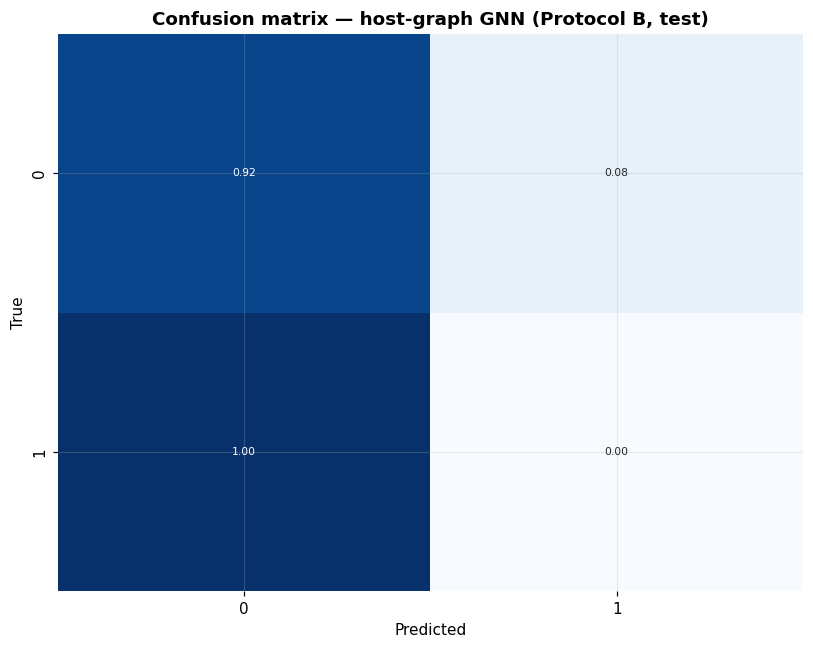

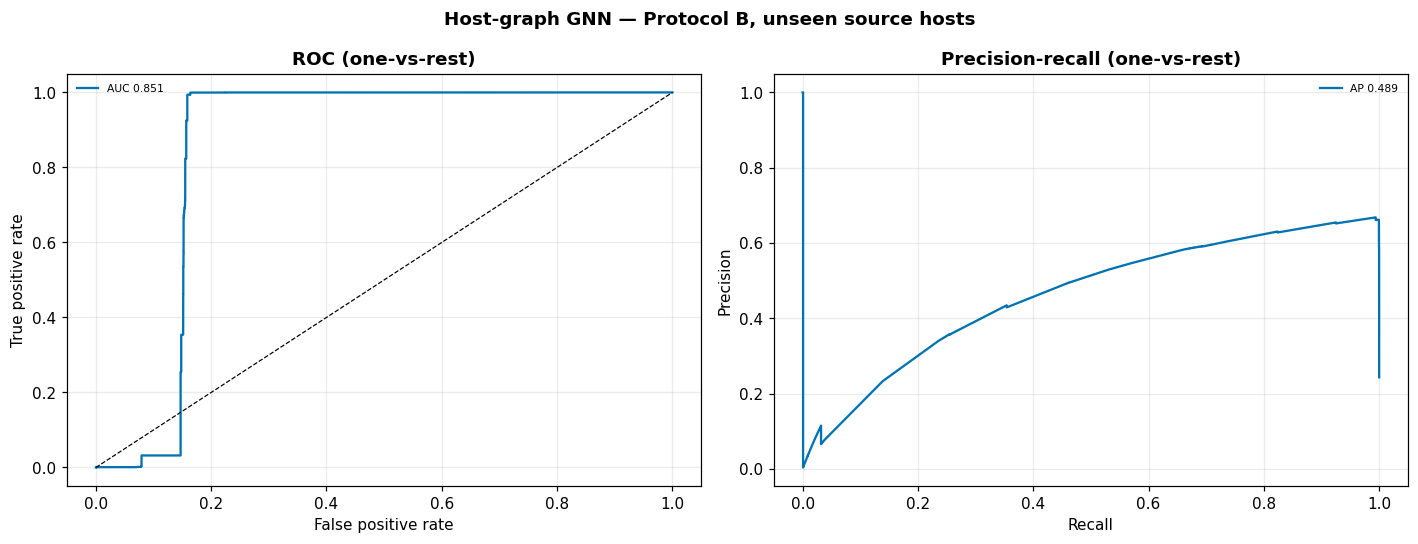

,val_macro_f1,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc,pr_auc,train_s
XGBoost (best baseline),0.9858,0.9904,0.9820,0.9926,0.9872,0.9905,0.9957,0.9849,1.6520
MLP control (no graph),0.9801,0.9915,0.9840,0.9933,0.9886,0.9916,0.9964,0.9739,26.5426
Host-graph GNN (ours),0.5859,0.6981,0.3738,0.4616,0.4122,0.6229,0.8505,0.4887,63.7269


In [14]:
LB = ["normal", "attack"]
df["_bin"] = df["label"].map({0: "normal", 1: "attack"})
gnn_B, r_gnn_B, hist_B, out_B, _ = train_gnn("B", LB, "_bin", n_layers=2)
ctl_B, r_ctl_B, _, out_ctl_B, _ = train_gnn("B", LB, "_bin", n_layers=0, tag=" control")
r_xgb_B, out_xgb_B = xgb_ref("B", LB, "_bin")
cmpB = pd.DataFrame({"XGBoost (best baseline)": r_xgb_B, "MLP control (no graph)": r_ctl_B,
                     "Host-graph GNN (ours)": r_gnn_B}).T[cols].astype(float)
cmpB.round(4).to_csv("comparison_B.csv")
yte, pred, prob = out_B
plot_cm(yte, pred, [0, 1], "Confusion matrix — host-graph GNN (Protocol B, test)", "gnn_B_cm")
plot_curves(yte, prob, LB, "Host-graph GNN — Protocol B, unseen source hosts", "gnn_B_curves")
cmpB.round(4)

## 6 · Save model and results

In [15]:
Path("models").mkdir(exist_ok=True)
torch.save(gnn_M.state_dict(), "models/Group07_TONIoT_gnn_M.pt")
torch.save(gnn_B.state_dict(), "models/Group07_TONIoT_gnn_B.pt")
with open("models/Group07_TONIoT_preprocessor_M.pkl", "wb") as f: pickle.dump(prep_M, f)
Path("models/label_map.json").write_text(json.dumps({"M": CLASSES, "B": LB}))
res = {"split_fingerprint": SPLIT_HASH, "nodes": N_NODES, "edges": int(len(df)),
       "protocol_M": cmpM.round(4).reset_index().to_dict("records"),
       "protocol_B": cmpB.round(4).reset_index().to_dict("records"),
       "per_class_recall_M": rec.round(4).to_dict()}
Path("gnn_results.json").write_text(json.dumps(res, indent=2, default=float))
print(json.dumps(res, indent=2, default=float)[:2500])

{
  "split_fingerprint": "70dd7b8009",
  "nodes": 776,
  "edges": 190474,
  "protocol_M": [
    {
      "index": "XGBoost (best baseline)",
      "val_macro_f1": 0.9553,
      "accuracy": 0.979,
      "macro_precision": 0.9404,
      "macro_recall": 0.9665,
      "macro_f1": 0.9509,
      "weighted_f1": 0.9794,
      "roc_auc": 0.9994,
      "pr_auc": 0.9785,
      "train_s": 40.483
    },
    {
      "index": "MLP control (no graph)",
      "val_macro_f1": 0.8827,
      "accuracy": 0.9393,
      "macro_precision": 0.8788,
      "macro_recall": 0.9337,
      "macro_f1": 0.8841,
      "weighted_f1": 0.9442,
      "roc_auc": 0.9952,
      "pr_auc": 0.9269,
      "train_s": 119.8358
    },
    {
      "index": "Host-graph GNN (ours)",
      "val_macro_f1": 0.622,
      "accuracy": 0.706,
      "macro_precision": 0.7728,
      "macro_recall": 0.7157,
      "macro_f1": 0.6262,
      "weighted_f1": 0.6708,
      "roc_auc": 0.9848,
      "pr_auc": 0.8954,
      "train_s": 61.2407
    }
  ],
 